<a href="https://colab.research.google.com/github/sebastianvettel1212/GrokkingDeepLearning/blob/main/08_Regularization_and_Batching.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 8 — Belajar Sinyal, Mengabaikan Noise: Regularisasi dan *Batching* (*Intro to Regularization and Batching*)

**Buku:** *Grokking Deep Learning* — Andrew W. Trask (Manning, 2019)

Kini jaringan kita menghadapi data nyata: **MNIST**, kumpulan gambar angka tulisan tangan. Kita akan melihat jaringan **menghafal** data latih (*overfitting*), lalu mempelajari cara mencegahnya: ***early stopping***, ***dropout***, dan ***batch gradient descent***. Kode diambil dari repositori resmi buku, ditambah teori dan eksperimen pendukung (berlabel *Tambahan*).

> **Catatan teknis.** Buku memakai `keras.datasets.mnist`. Di notebook ini fungsi `load_mnist()` mencoba Keras lebih dulu, lalu memakai salinan MNIST di GitHub bila Keras tidak tersedia. Dataset-nya sama. Pada kode buku, keluaran per-iterasi diperpendek (dicetak tiap beberapa iterasi) agar notebook mudah dibaca.

---

## Daftar Isi
0. Persiapan: Memuat MNIST
1. *Three-Layer Network* pada MNIST
2. "Well, That Was Easy": Memorisasi vs Generalisasi
3. *Overfitting* pada Neural Network dan Asalnya
4. Regularisasi Paling Sederhana: *Early Stopping*
5. Regularisasi Standar Industri: *Dropout*
6. Mengapa *Dropout* Bekerja: *Ensembling*
7. *Dropout* dalam Kode dan Evaluasi pada MNIST
8. *Batch Gradient Descent*
9. Tanya-Jawab Konsep dan Latihan
10. Ringkasan Bab

## 0. Persiapan: Memuat MNIST

In [1]:
import os, gzip, pickle, urllib.request, warnings
import numpy as np
warnings.filterwarnings('ignore')

def load_mnist():
    """Memuat MNIST. Mencoba Keras dahulu (seperti di buku); bila tidak tersedia,
    memakai salinan MNIST di GitHub (mnielsen/neural-networks-and-deep-learning)."""
    try:
        from keras.datasets import mnist
        return mnist.load_data()
    except Exception:
        url = ('https://github.com/mnielsen/neural-networks-and-deep-learning/'
               'raw/master/data/mnist.pkl.gz')
        if not os.path.exists('mnist.pkl.gz'):
            urllib.request.urlretrieve(url, 'mnist.pkl.gz')
        with gzip.open('mnist.pkl.gz', 'rb') as f:
            tr, va, te = pickle.load(f, encoding='latin1')
        x_train = np.concatenate([tr[0], va[0]]).reshape(-1, 28, 28) * 255
        y_train = np.concatenate([tr[1], va[1]])
        return (x_train, y_train), (te[0].reshape(-1, 28, 28) * 255, te[1])

In [2]:
import sys, time
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = load_mnist()
print('x_train:', x_train.shape, '| x_test:', x_test.shape, '| rentang piksel:', x_train.min(), '-', x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train: (60000, 28, 28) | x_test: (10000, 28, 28) | rentang piksel: 0 - 255


**MNIST:** 60.000 gambar latih dan 10.000 gambar uji berukuran 28×28 piksel (784 fitur), berlabel angka 0–9. Pada buku, hanya **1.000 gambar pertama** dipakai untuk melatih (agar *overfitting* mudah terlihat), sedangkan evaluasi dilakukan pada **10.000 gambar uji**.

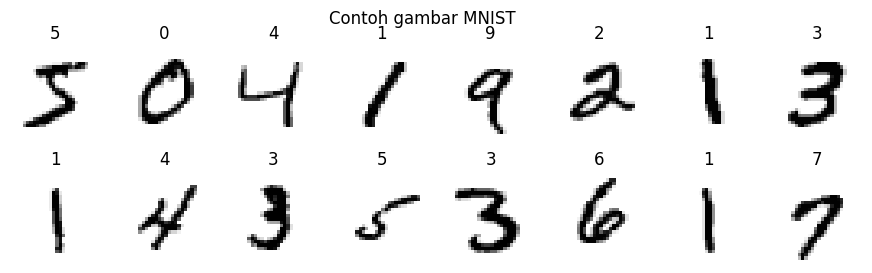

jumlah per kelas pada 1.000 data latih: [ 97 116  99  93 105  92  94 117  87 100]


In [3]:
# Tambahan (tidak ada di buku): contoh gambar dan distribusi kelas pada 1.000 data latih
fig, axes = plt.subplots(2, 8, figsize=(11, 3))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(x_train[k], cmap='gray_r'); ax.set_title(str(y_train[k])); ax.axis('off')
plt.suptitle('Contoh gambar MNIST'); plt.show()
print('jumlah per kelas pada 1.000 data latih:', np.bincount(y_train[:1000]))

---
## 1. *Three-Layer Network* pada MNIST

**Prapemrosesan:**
- Piksel dibagi 255 sehingga nilai berada di 0–1.
- Label diubah menjadi ***one-hot*** (vektor 10 elemen dengan satu angka 1) agar cocok dengan 10 node output.

**Arsitektur:** 784 input → *hidden layer* 40 node (ReLU) → 10 output. Tiap output adalah "skor" satu angka; prediksi adalah output dengan nilai terbesar (`argmax`). Pelatihan memakai *stochastic gradient descent* (satu gambar per pembaruan) persis seperti Bab 6.

In [4]:
images, labels = (x_train[0:1000].reshape(1000, 28*28) / 255, y_train[0:1000])

one_hot_labels = np.zeros((len(labels), 10))
for i, l in enumerate(labels):
    one_hot_labels[i][l] = 1
labels = one_hot_labels

test_images = x_test.reshape(len(x_test), 28*28) / 255
test_labels = np.zeros((len(y_test), 10))
for i, l in enumerate(y_test):
    test_labels[i][l] = 1

np.random.seed(1)
relu = lambda x: (x >= 0) * x          # returns x if x > 0, return 0 otherwise
relu2deriv = lambda x: x >= 0          # returns 1 for input > 0, return 0 otherwise
alpha, iterations, hidden_size, pixels_per_image, num_labels = (0.005, 350, 40, 784, 10)

weights_0_1 = 0.2 * np.random.random((pixels_per_image, hidden_size)) - 0.1
weights_1_2 = 0.2 * np.random.random((hidden_size, num_labels)) - 0.1

for j in range(iterations):
    error, correct_cnt = (0.0, 0)

    for i in range(len(images)):
        layer_0 = images[i:i+1]
        layer_1 = relu(np.dot(layer_0, weights_0_1))
        layer_2 = np.dot(layer_1, weights_1_2)

        error += np.sum((labels[i:i+1] - layer_2) ** 2)
        correct_cnt += int(np.argmax(layer_2) == np.argmax(labels[i:i+1]))

        layer_2_delta = (labels[i:i+1] - layer_2)
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)
        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)

    if j % 50 == 0 or j == iterations - 1:
        print("I:" + str(j) + " Train-Err:" + str(error / float(len(images)))[0:5] +
              " Train-Acc:" + str(correct_cnt / float(len(images))))

I:0 Train-Err:0.722 Train-Acc:0.537
I:50 Train-Err:0.204 Train-Acc:0.966
I:100 Train-Err:0.166 Train-Acc:0.984
I:150 Train-Err:0.145 Train-Acc:0.991
I:200 Train-Err:0.130 Train-Acc:0.998
I:250 Train-Err:0.120 Train-Acc:0.999
I:300 Train-Err:0.113 Train-Acc:0.999
I:349 Train-Err:0.108 Train-Acc:1.0


**Interpretasi:** pada data latih, error turun ke hampir 0 dan akurasi mendekati **100%**: jaringan seolah sudah "menguasai" data. Tetapi ini baru separuh cerita: bagaimana pada data yang belum pernah dilihat?

In [5]:
# Evaluasi pada 10.000 gambar uji dengan bobot akhir
error, correct_cnt = (0.0, 0)

for i in range(len(test_images)):
    layer_0 = test_images[i:i+1]
    layer_1 = relu(np.dot(layer_0, weights_0_1))
    layer_2 = np.dot(layer_1, weights_1_2)

    error += np.sum((test_labels[i:i+1] - layer_2) ** 2)
    correct_cnt += int(np.argmax(layer_2) == np.argmax(test_labels[i:i+1]))

print(" Test-Err:" + str(error / float(len(test_images)))[0:5] +
      " Test-Acc:" + str(correct_cnt / float(len(test_images))))

 Test-Err:0.653 Test-Acc:0.7073


---
## 2. "Well, That Was Easy": Memorisasi vs Generalisasi

Hasilnya mengejutkan: akurasi latih ≈ 100%, tetapi akurasi uji jauh lebih rendah. Dua istilah kunci:

- ***Memorization* (menghafal):** jaringan menyimpan ciri-ciri khusus 1.000 gambar latih, termasuk kebetulan dan noise yang tidak berlaku pada gambar lain.
- ***Generalization* (menggeneralisasi):** jaringan menangkap pola yang berlaku **umum** (bentuk angka), sehingga bekerja pada gambar baru.

**Analogi cetakan (*mold*):** bayangkan jaringan sebagai lempung yang ditekan ke gambar latih. Bila lempung terlalu "pas" mengikuti setiap lekuk gambar latih (termasuk lekuk yang cuma kebetulan), cetakannya bagus untuk gambar itu saja, tetapi tidak cocok untuk gambar baru. Kita menginginkan cetakan yang menangkap **bentuk umum**.

Cara memeriksanya selalu sama: **ukur performa pada data yang tidak dipakai untuk melatih** (*test set*). Pada eksperimen berikutnya kita merekam akurasi latih dan uji pada setiap tahap pelatihan.

In [6]:
# Versi dengan evaluasi uji tiap 10 iterasi (kode buku) + riwayat untuk grafik (penambahan: list `riwayat`)
np.random.seed(1)
relu = lambda x: (x >= 0) * x
relu2deriv = lambda x: x >= 0
alpha, iterations, hidden_size, pixels_per_image, num_labels = (0.005, 350, 40, 784, 10)

weights_0_1 = 0.2 * np.random.random((pixels_per_image, hidden_size)) - 0.1
weights_1_2 = 0.2 * np.random.random((hidden_size, num_labels)) - 0.1
riwayat = []                                                    # (iterasi, train_acc, test_acc)

for j in range(iterations):
    error, correct_cnt = (0.0, 0)

    for i in range(len(images)):
        layer_0 = images[i:i+1]
        layer_1 = relu(np.dot(layer_0, weights_0_1))
        layer_2 = np.dot(layer_1, weights_1_2)

        error += np.sum((labels[i:i+1] - layer_2) ** 2)
        correct_cnt += int(np.argmax(layer_2) == np.argmax(labels[i:i+1]))

        layer_2_delta = (labels[i:i+1] - layer_2)
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)
        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)

    if j % 10 == 0 or j == iterations - 1:
        t_error, t_correct_cnt = (0.0, 0)

        for i in range(len(test_images)):
            layer_0 = test_images[i:i+1]
            layer_1 = relu(np.dot(layer_0, weights_0_1))
            layer_2 = np.dot(layer_1, weights_1_2)

            t_error += np.sum((test_labels[i:i+1] - layer_2) ** 2)
            t_correct_cnt += int(np.argmax(layer_2) == np.argmax(test_labels[i:i+1]))
        riwayat.append((j, correct_cnt / float(len(images)), t_correct_cnt / float(len(test_images))))
        if j % 50 == 0 or j == iterations - 1:
            print("I:" + str(j) + " Train-Err:" + str(error / float(len(images)))[0:5] +
                  " Train-Acc:" + str(correct_cnt / float(len(images))) +
                  " Test-Err:" + str(t_error / float(len(test_images)))[0:5] +
                  " Test-Acc:" + str(t_correct_cnt / float(len(test_images))))

I:0 Train-Err:0.722 Train-Acc:0.537 Test-Err:0.601 Test-Acc:0.6488
I:50 Train-Err:0.204 Train-Acc:0.966 Test-Err:0.437 Test-Acc:0.7982
I:100 Train-Err:0.166 Train-Acc:0.984 Test-Err:0.482 Test-Acc:0.7706
I:150 Train-Err:0.145 Train-Acc:0.991 Test-Err:0.513 Test-Acc:0.7558
I:200 Train-Err:0.130 Train-Acc:0.998 Test-Err:0.538 Test-Acc:0.7464
I:250 Train-Err:0.120 Train-Acc:0.999 Test-Err:0.577 Test-Acc:0.7316
I:300 Train-Err:0.113 Train-Acc:0.999 Test-Err:0.614 Test-Acc:0.7183
I:349 Train-Err:0.108 Train-Acc:1.0 Test-Err:0.653 Test-Acc:0.7073


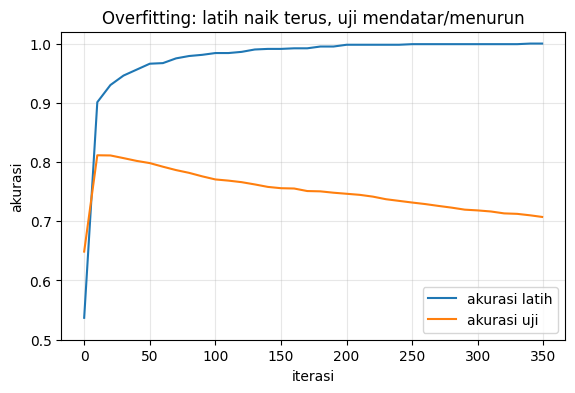

Akurasi uji tertinggi 0.8114 pada iterasi 10; akurasi uji akhir 0.7073; akurasi latih akhir 1.000


In [7]:
# Tambahan (tidak ada di buku): kurva akurasi latih vs uji
r = np.array(riwayat)
plt.figure(figsize=(6.5, 4))
plt.plot(r[:, 0], r[:, 1], label='akurasi latih')
plt.plot(r[:, 0], r[:, 2], label='akurasi uji')
plt.xlabel('iterasi'); plt.ylabel('akurasi'); plt.ylim(0.5, 1.02); plt.grid(alpha=0.3); plt.legend()
plt.title('Overfitting: latih naik terus, uji mendatar/menurun')
plt.show()
i_best = int(np.argmax(r[:, 2]))
print(f'Akurasi uji tertinggi {r[i_best, 2]:.4f} pada iterasi {int(r[i_best, 0])}; '
      f'akurasi uji akhir {r[-1, 2]:.4f}; akurasi latih akhir {r[-1, 1]:.3f}')

**Interpretasi:** akurasi **latih** naik terus hingga 100%, sedangkan akurasi **uji** mencapai puncak ≈ 81,2% pada iterasi ke-10, lalu justru **menurun** hingga ≈ 70,8% di akhir. Jarak antara kedua kurva adalah ukuran ***overfitting***: setelah titik terbaik, setiap iterasi tambahan membuat jaringan semakin menghafal data latih dan semakin buruk pada data baru.

---
## 3. *Overfitting* pada Neural Network dan Asalnya

Dari mana *overfitting* berasal? Neural network berisi **banyak parameter** (di sini 784×40 + 40×10 = 31.760) dibanding data latih yang sedikit (1.000 gambar). Ketika parameter jauh lebih banyak daripada informasi yang benar-benar bersifat umum, jaringan punya cukup "ruang" untuk **menghafal kebetulan**.

Analogi persamaan: bila kita hanya punya 2 titik data, banyak garis/lengkungan berbeda yang melewati keduanya dengan sempurna. Tidak ada cara membedakan yang "benar" dari yang "kebetulan". Makin sedikit data per parameter, makin banyak solusi yang tampak sempurna di data latih namun salah di data baru. Karena itu **menambah data** adalah obat paling efektif. Mari buktikan.

In [8]:
# Tambahan (tidak ada di buku): trainer vektorisasi minibatch untuk eksperimen (perilaku sama dengan kode buku)
def one_hot(y, k=10):
    o = np.zeros((len(y), k)); o[np.arange(len(y)), y] = 1; return o

def train_mlp(X, Y, Xt, Yt, hidden=40, alpha=0.005, iters=60, batch=1, dropout=False,
              seed=1, every=5, Xv=None, Yv=None):
    rng = np.random.RandomState(seed)
    w01 = 0.2 * rng.random_sample((784, hidden)) - 0.1
    w12 = 0.2 * rng.random_sample((hidden, 10)) - 0.1
    hist = []
    acc = lambda A, B: (np.argmax(relu(A @ w01) @ w12, 1) == np.argmax(B, 1)).mean()
    for j in range(iters):
        for s in range(0, len(X), batch):
            l0 = X[s:s+batch]
            l1 = relu(l0 @ w01)
            if dropout:
                mask = rng.randint(2, size=l1.shape); l1 = l1 * mask * 2
            l2 = l1 @ w12
            d2 = (Y[s:s+batch] - l2) / batch
            d1 = d2 @ w12.T * relu2deriv(l1)
            if dropout: d1 = d1 * mask
            w12 += alpha * l1.T @ d2
            w01 += alpha * l0.T @ d1
        if j % every == 0 or j == iters - 1:
            hist.append((j, acc(X, Y), acc(Xt, Yt), acc(Xv, Yv) if Xv is not None else np.nan))
    return w01, w12, np.array(hist)

Xtr_all = x_train.reshape(-1, 784) / 255; Ytr_all = one_hot(y_train)
rows = []
for n_data in [100, 1000, 5000]:
    t0 = time.time()
    _, _, h = train_mlp(Xtr_all[:n_data], Ytr_all[:n_data], test_images, test_labels, iters=60, every=60)
    rows.append((n_data, h[-1, 1], h[-1, 2], time.time() - t0))
print('data latih | akurasi latih | akurasi uji | selisih (overfitting) | waktu')
for n_data, tr, te, dt in rows:
    print(f'{n_data:10d} | {tr:13.3f} | {te:11.3f} | {tr - te:21.3f} | {dt:4.1f}s')

data latih | akurasi latih | akurasi uji | selisih (overfitting) | waktu
       100 |         1.000 |       0.625 |                 0.375 |  0.9s
      1000 |         0.971 |       0.793 |                 0.178 |  9.6s
      5000 |         0.927 |       0.876 |                 0.051 | 43.4s


**Interpretasi:** dengan 100 gambar, akurasi latih 100% tetapi akurasi uji hanya ≈ 62,5% (selisih ≈ 0,38); dengan 1.000 gambar selisihnya ≈ 0,18 (uji ≈ 79,3%); dengan 5.000 gambar selisihnya hanya ≈ 0,05 (uji ≈ 87,7%). Makin banyak data, makin kecil celah antara latih dan uji dan makin tinggi akurasi uji. Sumber *overfitting* memang rasio parameter terhadap data. (Setiap konfigurasi dilatih 60 iterasi.)

---
## 4. Regularisasi Paling Sederhana: *Early Stopping*

***Regularisasi*** adalah metode yang membantu model **menggeneralisasi**, bukan menghafal. Yang paling sederhana: ***early stopping***, yaitu **berhenti melatih saat performa pada data yang tidak dipakai untuk melatih berhenti membaik** (pada kurva di atas: mendekati puncak kurva uji).

> **Peringatan:** memilih titik berhenti dengan *test set* sama dengan "mengintip" soal ujian, sehingga skor uji menjadi terlalu optimis. Cara yang benar memakai ***validation set*** terpisah: pilih iterasi terbaik dari validasi, lalu laporkan skor di test set sekali saja.

Iterasi terbaik menurut VALIDASI: 6 (akurasi validasi 0.815)
Akurasi UJI pada titik itu     : 0.8012
Akurasi UJI jika berlatih terus : 0.7708  (iterasi 99)


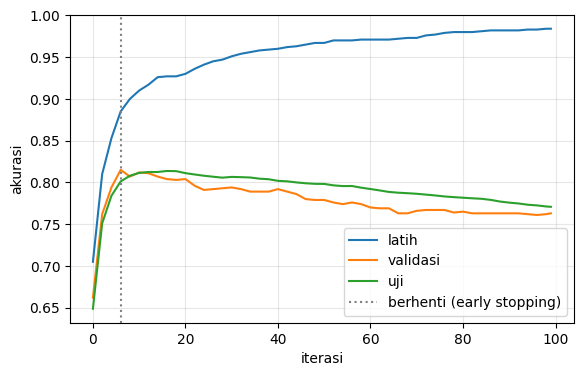

In [9]:
# Tambahan (tidak ada di buku): early stopping yang benar memakai validation set terpisah
Xtr, Ytr = Xtr_all[:1000], Ytr_all[:1000]
Xval, Yval = Xtr_all[1000:2000], Ytr_all[1000:2000]

_, _, h = train_mlp(Xtr, Ytr, test_images, test_labels, iters=100, every=2, Xv=Xval, Yv=Yval)
best = int(np.argmax(h[:, 3]))
print(f'Iterasi terbaik menurut VALIDASI: {int(h[best, 0])} (akurasi validasi {h[best, 3]:.3f})')
print(f'Akurasi UJI pada titik itu     : {h[best, 2]:.4f}')
print(f'Akurasi UJI jika berlatih terus : {h[-1, 2]:.4f}  (iterasi {int(h[-1, 0])})')

plt.figure(figsize=(6.5, 4))
plt.plot(h[:, 0], h[:, 1], label='latih'); plt.plot(h[:, 0], h[:, 3], label='validasi'); plt.plot(h[:, 0], h[:, 2], label='uji')
plt.axvline(h[best, 0], color='gray', linestyle=':', label='berhenti (early stopping)')
plt.xlabel('iterasi'); plt.ylabel('akurasi'); plt.legend(); plt.grid(alpha=0.3); plt.show()

**Interpretasi:** akurasi validasi mencapai puncak sangat awal (iterasi ke-6, ≈ 81,4%). Berhenti di titik itu memberi akurasi uji ≈ 80,1%, **lebih baik** daripada berlatih sampai iterasi ke-99 (≈ 77,1%), dan jauh lebih murah secara komputasi. Kelemahannya: *early stopping* hanya **menghentikan** hafalan, belum mencegahnya.

---
## 5. Regularisasi Standar Industri: *Dropout*

***Dropout*** mematikan sebagian node **secara acak** selama pelatihan. Pada tiap contoh latih:
1. Buat ***dropout mask***: vektor acak berisi 0 dan 1 (peluang 50%).
2. Kalikan `layer_1` dengan mask (node bernilai 0 "dimatikan" untuk contoh itu).
3. Kalikan sisanya dengan **2** (`1/peluang bertahan`) agar **total sinyal yang diharapkan tetap sama**.
4. Saat *backpropagation*, delta juga dikalikan mask: node yang mati tidak ikut diperbarui.
5. Saat **evaluasi/prediksi**, dropout **dimatikan** (tanpa mask dan tanpa penggandaan).

Ilustrasi pada satu gambar, memakai jaringan terlatih di atas:

In [10]:
# Dropout pada satu contoh (versi ringkas dari kode buku; memakai jaringan terlatih di atas)
np.random.seed(1)
i = 0
layer_0 = images[i:i+1]
layer_1 = relu(np.dot(layer_0, weights_0_1))
dropout_mask = np.random.randint(2, size=layer_1.shape)
layer_1_dropout = layer_1 * dropout_mask * 2

print('layer_1 asli       :', layer_1.round(2).ravel()[:10], '...')
print('dropout_mask       :', dropout_mask.ravel()[:10], '...')
print('layer_1 + dropout  :', layer_1_dropout.round(2).ravel()[:10], '...')

# Tambahan: rata-rata banyak mask = nilai asli (sinyal yang diharapkan tetap sama)
rata2 = np.mean([layer_1 * np.random.randint(2, size=layer_1.shape) * 2 for _ in range(20000)], axis=0)
print('selisih maksimum |rata-rata dropout - asli| =', np.abs(rata2 - layer_1).max().round(4))

layer_1 asli       : [-0.   0.3 -0.  -0.  -0.  -0.   0.1 -0.  -0.  -0. ] ...
dropout_mask       : [1 1 0 0 1 1 1 1 1 0] ...
layer_1 + dropout  : [-0.    0.61 -0.   -0.   -0.   -0.    0.21 -0.   -0.   -0.  ] ...
selisih maksimum |rata-rata dropout - asli| = 0.0054


**Interpretasi:** sekitar separuh node menjadi 0 dan sisanya digandakan. Rata-rata dari banyak *mask* kembali mendekati nilai asli (selisih kecil), sehingga dropout tidak "menggeser" skala sinyal. Saat prediksi, kita memakai `layer_1` asli tanpa mask.

---
## 6. Mengapa *Dropout* Bekerja: *Ensembling*

Intuisi bab: setiap kali sebagian node dimatikan, kita sebenarnya melatih **jaringan kecil yang berbeda** (sub-jaringan) dengan bobot yang **dipakai bersama**. Pada hasil akhir, jaringan penuh bertindak seperti **ensemble**: rata-rata prediksi banyak jaringan.

Mengapa ensemble menggeneralisasi lebih baik?
- Tiap jaringan punya **kesalahan acak yang berbeda** (terutama kesalahan akibat menghafal noise), dan rata-rata menghilangkan kesalahan acak tersebut.
- Sinyal yang konsisten (pola umum) diperkuat, sedangkan hafalan yang kebetulan melemah.
- Node tidak bisa "bersandar" pada node tertentu (***co-adaptation***) karena sewaktu-waktu node itu mati; tiap node dipaksa belajar fitur yang berguna sendiri.

Analogi buku: bila beberapa orang dibiarkan mencoba menyelesaikan teka-teki (masing-masing menguasai potongan berbeda) lalu hasilnya digabung, hasilnya lebih andal dibanding satu orang yang kebetulan menghafal satu cara.

---
## 7. *Dropout* dalam Kode dan Evaluasi pada MNIST

Pelatihan penuh dengan dropout: *hidden layer* diperbesar menjadi 100 node (dropout membuat jaringan lebih besar tetap aman), 300 iterasi.

In [11]:
import numpy
np.random.seed(1)
def relu(x):
    return (x >= 0) * x # returns x if x > 0
                        # returns 0 otherwise

def relu2deriv(output):
    return output >= 0 #returns 1 for input > 0

alpha, iterations, hidden_size = (0.005, 300, 100)
pixels_per_image, num_labels = (784, 10)

weights_0_1 = 0.2 * np.random.random((pixels_per_image, hidden_size)) - 0.1
weights_1_2 = 0.2 * np.random.random((hidden_size, num_labels)) - 0.1

for j in range(iterations):
    error, correct_cnt = (0.0, 0)
    for i in range(len(images)):
        layer_0 = images[i:i+1]
        layer_1 = relu(np.dot(layer_0, weights_0_1))
        dropout_mask = np.random.randint(2, size=layer_1.shape)
        layer_1 *= dropout_mask * 2
        layer_2 = np.dot(layer_1, weights_1_2)

        error += np.sum((labels[i:i+1] - layer_2) ** 2)
        correct_cnt += int(np.argmax(layer_2) == np.argmax(labels[i:i+1]))
        layer_2_delta = (labels[i:i+1] - layer_2)
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)
        layer_1_delta *= dropout_mask

        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)

    if(j % 10 == 0):
        test_error = 0.0
        test_correct_cnt = 0

        for i in range(len(test_images)):
            layer_0 = test_images[i:i+1]
            layer_1 = relu(np.dot(layer_0, weights_0_1))
            layer_2 = np.dot(layer_1, weights_1_2)

            test_error += np.sum((test_labels[i:i+1] - layer_2) ** 2)
            test_correct_cnt += int(np.argmax(layer_2) == np.argmax(test_labels[i:i+1]))

        if j % 50 == 0 or j == iterations - 10:
            sys.stdout.write("\n" + "I:" + str(j) +
                             " Test-Err:" + str(test_error / float(len(test_images)))[0:5] +
                             " Test-Acc:" + str(test_correct_cnt / float(len(test_images))) +
                             " Train-Err:" + str(error / float(len(images)))[0:5] +
                             " Train-Acc:" + str(correct_cnt / float(len(images))))
print()


I:0 Test-Err:0.641 Test-Acc:0.6333 Train-Err:0.891 Train-Acc:0.413
I:50 Test-Err:0.409 Test-Acc:0.8133 Train-Err:0.392 Train-Acc:0.836
I:100 Test-Err:0.411 Test-Acc:0.7903 Train-Err:0.369 Train-Acc:0.864
I:150 Test-Err:0.404 Test-Acc:0.8107 Train-Err:0.342 Train-Acc:0.883
I:200 Test-Err:0.405 Test-Acc:0.8036 Train-Err:0.347 Train-Acc:0.893
I:250 Test-Err:0.395 Test-Acc:0.8182 Train-Err:0.320 Train-Acc:0.899
I:290 Test-Err:0.399 Test-Acc:0.8181 Train-Err:0.301 Train-Acc:0.908


**Interpretasi:** akurasi **latih** (yang dihitung dengan dropout aktif) sengaja lebih rendah dan lebih "berisik", sedangkan akurasi uji ditentukan oleh kemampuan menggeneralisasi; bandingkan dengan jaringan tanpa dropout pada eksperimen terkontrol berikut: jaringan 100 node dengan dan tanpa dropout, kondisi lain sama.

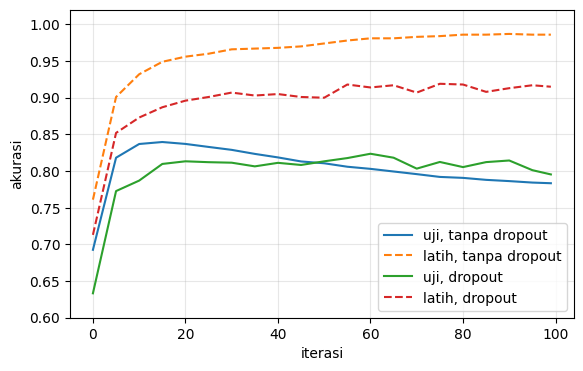

Akhir tanpa dropout : latih 0.986 | uji 0.7834 | selisih 0.203
Akhir dengan dropout: latih 0.915 | uji 0.7954 | selisih 0.120


In [12]:
# Tambahan (tidak ada di buku): dropout vs tanpa dropout (hidden 100, 100 iterasi)
relu = lambda x: (x >= 0) * x
relu2deriv = lambda x: x >= 0
_, _, h_no = train_mlp(Xtr, Ytr, test_images, test_labels, hidden=100, iters=100, every=5, dropout=False)
_, _, h_do = train_mlp(Xtr, Ytr, test_images, test_labels, hidden=100, iters=100, every=5, dropout=True)

plt.figure(figsize=(6.5, 4))
plt.plot(h_no[:, 0], h_no[:, 2], label='uji, tanpa dropout'); plt.plot(h_no[:, 0], h_no[:, 1], '--', label='latih, tanpa dropout')
plt.plot(h_do[:, 0], h_do[:, 2], label='uji, dropout');       plt.plot(h_do[:, 0], h_do[:, 1], '--', label='latih, dropout')
plt.xlabel('iterasi'); plt.ylabel('akurasi'); plt.ylim(0.6, 1.02); plt.grid(alpha=0.3); plt.legend(); plt.show()
print(f'Akhir tanpa dropout : latih {h_no[-1,1]:.3f} | uji {h_no[-1,2]:.4f} | selisih {h_no[-1,1]-h_no[-1,2]:.3f}')
print(f'Akhir dengan dropout: latih {h_do[-1,1]:.3f} | uji {h_do[-1,2]:.4f} | selisih {h_do[-1,1]-h_do[-1,2]:.3f}')

**Interpretasi:** pada kondisi yang sama (100 hidden node, 100 iterasi), dropout menurunkan akurasi latih (0,986 → 0,913) tetapi **menaikkan akurasi uji** (0,783 → 0,796) dan menyempitkan selisih latih-uji dari ≈ 0,20 menjadi ≈ 0,12. Pada pelatihan penuh 300 iterasi (bagian atas), akurasi uji dengan dropout stabil di sekitar 80–82% dan tidak lagi menurun seperti jaringan tanpa dropout pada kurva bagian 2 (yang turun sampai ≈ 71%; catatan: arsitektur kedua jaringan itu tidak persis sama).

---
## 8. *Batch Gradient Descent*

Sejauh ini bobot diperbarui **setelah tiap gambar** (*stochastic*). Alternatif: memperbarui bobot **setelah sekelompok gambar** (*mini-batch*), memakai **rata-rata gradien** kelompok itu (di kode: delta dibagi `batch_size`).

**Keuntungan:**
1. **Sinyal lebih stabil:** rata-rata 100 gradien meredam noise dari contoh tunggal, sehingga lintasan belajar lebih mulus.
2. **Jauh lebih cepat:** operasi matriks pada 100 contoh sekaligus memanfaatkan vektorisasi (Bab 1) dibanding 100 pembaruan terpisah.

> **Dua catatan kode.** (1) Pada notebook resmi, baris pembaruan bobot ikut menjorok ke dalam loop penghitung akurasi (`for k in range(batch_size)`), sehingga bobot diperbarui 100 kali per batch (dan pelatihan menjadi sangat lambat). Listing di buku menempatkannya sekali per batch; itu yang dipakai di sini. (2) Listing buku mencetak `alpha = 0.001`, tetapi teks di bawahnya menyebut `alpha` kini **20 kali lebih besar** daripada sebelumnya (0,005 → 0,1). Karena gradien dirata-ratakan, `alpha` boleh lebih besar. Di sini dipakai `alpha = 0.1`; perbandingan dengan 0,001 ada pada eksperimen di bawah.

In [13]:
import numpy as np
np.random.seed(1)

def relu(x):
    return (x >= 0) * x # returns x if x > 0

def relu2deriv(output):
    return output >= 0 # returns 1 for input > 0

batch_size = 100
alpha, iterations = (0.1, 300)          # buku: teks menyebut alpha 20x lebih besar -> 0.1
pixels_per_image, num_labels, hidden_size = (784, 10, 100)

weights_0_1 = 0.2 * np.random.random((pixels_per_image, hidden_size)) - 0.1
weights_1_2 = 0.2 * np.random.random((hidden_size, num_labels)) - 0.1

for j in range(iterations):
    error, correct_cnt = (0.0, 0)
    for i in range(int(len(images) / batch_size)):
        batch_start, batch_end = ((i * batch_size), ((i + 1) * batch_size))

        layer_0 = images[batch_start:batch_end]
        layer_1 = relu(np.dot(layer_0, weights_0_1))
        dropout_mask = np.random.randint(2, size=layer_1.shape)
        layer_1 *= dropout_mask * 2
        layer_2 = np.dot(layer_1, weights_1_2)

        error += np.sum((labels[batch_start:batch_end] - layer_2) ** 2)
        for k in range(batch_size):
            correct_cnt += int(np.argmax(layer_2[k:k+1]) == np.argmax(labels[batch_start+k:batch_start+k+1]))

        # pembaruan bobot SEKALI per batch (di luar loop k)
        layer_2_delta = (labels[batch_start:batch_end] - layer_2) / batch_size
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)
        layer_1_delta *= dropout_mask

        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)

    if(j % 10 == 0):
        test_error = 0.0
        test_correct_cnt = 0

        for i in range(len(test_images)):
            layer_0 = test_images[i:i+1]
            layer_1 = relu(np.dot(layer_0, weights_0_1))
            layer_2 = np.dot(layer_1, weights_1_2)

            test_error += np.sum((test_labels[i:i+1] - layer_2) ** 2)
            test_correct_cnt += int(np.argmax(layer_2) == np.argmax(test_labels[i:i+1]))

        if j % 50 == 0 or j == iterations - 10:
            sys.stdout.write("\n" + "I:" + str(j) +
                             " Test-Err:" + str(test_error / float(len(test_images)))[0:5] +
                             " Test-Acc:" + str(test_correct_cnt / float(len(test_images))) +
                             " Train-Err:" + str(error / float(len(images)))[0:5] +
                             " Train-Acc:" + str(correct_cnt / float(len(images))))
print()


I:0 Test-Err:0.815 Test-Acc:0.3832 Train-Err:1.272 Train-Acc:0.161
I:50 Test-Err:0.453 Test-Acc:0.7978 Train-Err:0.462 Train-Acc:0.784
I:100 Test-Err:0.437 Test-Acc:0.8029 Train-Err:0.436 Train-Acc:0.805
I:150 Test-Err:0.437 Test-Acc:0.7967 Train-Err:0.410 Train-Acc:0.818
I:200 Test-Err:0.430 Test-Acc:0.8089 Train-Err:0.415 Train-Acc:0.844
I:250 Test-Err:0.424 Test-Acc:0.8074 Train-Err:0.385 Train-Acc:0.851
I:290 Test-Err:0.418 Test-Acc:0.806 Train-Err:0.375 Train-Acc:0.862


In [14]:
# Tambahan (tidak ada di buku): kecepatan stochastic (batch=1) vs mini-batch (batch=100), 20 iterasi
t0 = time.time(); _, _, h1 = train_mlp(Xtr, Ytr, test_images, test_labels, hidden=100, iters=20, batch=1, every=19)
t1 = time.time() - t0
t0 = time.time(); _, _, h100 = train_mlp(Xtr, Ytr, test_images, test_labels, hidden=100, alpha=0.1, iters=20, batch=100, every=19)
t100 = time.time() - t0
print(f'batch=1   : {t1:6.2f} detik | akurasi uji {h1[-1,2]:.3f}')
print(f'batch=100 : {t100:6.2f} detik | akurasi uji {h100[-1,2]:.3f} | ~{t1/t100:.0f}x lebih cepat')

batch=1   :   7.93 detik | akurasi uji 0.839
batch=100 :   0.57 detik | akurasi uji 0.808 | ~14x lebih cepat


In [15]:
# Tambahan (tidak ada di buku): alpha yang dicetak di listing (0.001) vs alpha 0.1 pada mini-batch (300 iterasi, dropout)
relu = lambda x: (x >= 0) * x
relu2deriv = lambda x: x >= 0
for a in [0.001, 0.1]:
    _, _, h = train_mlp(Xtr, Ytr, test_images, test_labels, hidden=100, alpha=a, iters=300, batch=100, dropout=True, every=299)
    print(f'alpha = {a:<6}: akurasi latih {h[-1,1]:.3f} | akurasi uji {h[-1,2]:.4f}')

alpha = 0.001 : akurasi latih 0.703 | akurasi uji 0.6092
alpha = 0.1   : akurasi latih 0.913 | akurasi uji 0.8116


**Interpretasi:** pada eksperimen pertama, 20 iterasi mini-batch selesai dalam ≈ 0,33 detik dibanding ≈ 3,7 detik untuk *stochastic* (batch = 1), yaitu ≈ 11× lebih cepat, karena vektorisasi. Pada eksperimen kedua (300 iterasi), `alpha = 0,001` seperti pada listing buku hanya mencapai akurasi uji ≈ 60,9% (belum selesai belajar), sedangkan `alpha = 0,1` mencapai ≈ 81,1%. Ini sesuai teks buku bahwa gradien yang dirata-ratakan memungkinkan `alpha` jauh lebih besar. Pada pelatihan di atas (bobot diperbarui sekali per batch, `alpha = 0,1`), akurasi uji akhir ≈ 80,6%. Konsekuensi lain mini-batch: dalam jumlah iterasi yang sama jaringan melakukan **lebih sedikit pembaruan bobot** (10 per iterasi, bukan 1.000), sehingga biasanya memerlukan lebih banyak iterasi atau `alpha` yang disesuaikan. Dalam praktik, mini-batch adalah standar karena kecepatan dan kestabilannya.

---
## 9. Tanya-Jawab Konsep dan Latihan

**1. Apa beda memorisasi dan generalisasi?** Memorisasi: jaringan mengingat detail khusus data latih (termasuk noise). Generalisasi: jaringan menangkap pola umum yang berlaku pada data baru.

**2. Mengapa akurasi latih tinggi belum menjamin model baik?** Karena model bisa menghafal; hanya performa pada data yang tidak dipakai untuk melatih yang menunjukkan kemampuan menggeneralisasi.

**3. Mengapa *dropout* menggandakan node yang bertahan?** Agar jumlah sinyal yang diharapkan masuk ke layer berikutnya tetap sama seperti tanpa dropout (terbukti numerik pada bagian 5).

**4. Mengapa dropout dimatikan saat prediksi?** Saat prediksi kita ingin keluaran stabil dan lengkap: memakai seluruh node (yang sudah merupakan "rata-rata" ensemble), bukan keluaran acak.

**5. Mengapa *early stopping* sebaiknya memakai validation set, bukan test set?** Memilih titik berhenti dari test set membuat test set ikut "dipakai belajar" sehingga skor uji tidak lagi jujur.

**6. Apa keuntungan *mini-batch*?** Gradien rata-rata lebih stabil dan komputasi jauh lebih cepat lewat vektorisasi.

### Latihan mandiri
1. Dengan `train_mlp`, bandingkan `hidden = 20, 100, 400` pada 1.000 data latih. Apakah jaringan lebih besar selalu overfit lebih parah?
2. Coba peluang dropout berbeda (mis. mempertahankan 80% node, penggandaan 1/0,8). Bagaimana pengaruhnya?
3. Jelaskan mengapa `layer_1_delta *= dropout_mask` diperlukan.

In [16]:
# Jawaban latihan mandiri (Tambahan)
relu = lambda x: (x >= 0) * x
relu2deriv = lambda x: x >= 0
print('1) pengaruh ukuran hidden layer (60 iterasi, tanpa dropout):')
for hsz in [20, 100, 400]:
    _, _, h = train_mlp(Xtr, Ytr, test_images, test_labels, hidden=hsz, iters=60, every=60)
    print(f'   hidden={hsz:4d} | latih {h[-1,1]:.3f} | uji {h[-1,2]:.4f} | selisih {h[-1,1]-h[-1,2]:.3f}')

def train_dropout_p(keep, iters=60, hidden=100, alpha=0.005):
    rng = np.random.RandomState(1)
    w01 = 0.2 * rng.random_sample((784, hidden)) - 0.1; w12 = 0.2 * rng.random_sample((hidden, 10)) - 0.1
    for _ in range(iters):
        for s in range(len(Xtr)):
            l0 = Xtr[s:s+1]; l1 = relu(l0 @ w01)
            mask = (rng.random_sample(l1.shape) < keep) / keep       # mask (peluang bertahan = keep), skala 1/keep
            l1 = l1 * mask; l2 = l1 @ w12
            d2 = Ytr[s:s+1] - l2; d1 = d2 @ w12.T * relu2deriv(l1) * (mask > 0)
            w12 += alpha * l1.T @ d2; w01 += alpha * l0.T @ d1
    return (np.argmax(relu(test_images @ w01) @ w12, 1) == np.argmax(test_labels, 1)).mean()

print('2) peluang bertahan node (keep) vs akurasi uji:')
for keep in [0.5, 0.8, 1.0]:
    print(f'   keep={keep}: uji = {train_dropout_p(keep):.4f}')
print('3) tanpa mengalikan mask pada delta, node yang dimatikan tetap menerima koreksi padahal tidak ikut menghasilkan prediksi (gradiennya salah).')

1) pengaruh ukuran hidden layer (60 iterasi, tanpa dropout):
   hidden=  20 | latih 0.974 | uji 0.7878 | selisih 0.186
   hidden= 100 | latih 0.980 | uji 0.8035 | selisih 0.176
   hidden= 400 | latih 0.998 | uji 0.8341 | selisih 0.164
2) peluang bertahan node (keep) vs akurasi uji:
   keep=0.5: uji = 0.8178
   keep=0.8: uji = 0.8036
   keep=1.0: uji = 0.8035
3) tanpa mengalikan mask pada delta, node yang dimatikan tetap menerima koreksi padahal tidak ikut menghasilkan prediksi (gradiennya salah).


---
## 10. Ringkasan Bab

- ***Overfitting*:** jaringan menghafal data latih (akurasi latih ≈ 100%, uji jauh lebih rendah). Penyebabnya parameter yang banyak relatif terhadap data; obat paling dasar adalah **lebih banyak data**.
- ***Early stopping*:** berhenti saat performa pada data di luar pelatihan berhenti membaik (pakai *validation set*).
- ***Dropout*:** mematikan 50% node secara acak (dan menggandakan sisanya) saat latihan; bekerja seperti **ensemble** banyak sub-jaringan.
- ***Mini-batch gradient descent*:** memperbarui bobot dengan rata-rata gradien sekelompok contoh; lebih stabil dan jauh lebih cepat.

### Rangkuman konsep
| Subbab | Konsep | Kode |
|---|---|---|
| MNIST 3-layer | One-hot, ReLU, 784→40→10 | `relu`, `argmax` |
| Overfitting | Latih vs uji | `riwayat`, kurva akurasi |
| Early stopping | Berhenti di puncak validasi | `train_mlp(..., Xv, Yv)` |
| Dropout | Mask acak ×2, delta × mask | `dropout_mask` |
| Ensemble | Rata-rata sub-jaringan | Penjelasan + eksperimen |
| Mini-batch | Rata-rata gradien | `batch_size`, delta ÷ `batch_size` |